In [1]:
## importing necessary modules 
import torch
from math import sqrt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE" ## For plotting inside .ipynb in VS code

In [2]:
## FISTA Algorithm

def FISTA(Vandermonde, y, epochs = 1000, lamb = 0.5, grad = lambda A, x, b: (A.T @ (A @ x - b)), cutoff = 0.5, lr = None): ## cutoff is the cutoff value for the least squares at the end
  x = torch.rand(size = (Vandermonde.shape[1],)).reshape(-1,1)
  if lr == None:
    lr = 1 / (torch.linalg.norm(Vandermonde.T @ Vandermonde, ord = 2)) ## lr guaranteeing convergence for fista

  Vandermonde = Vandermonde
  soft_thres = lambda x, th = lamb * lr: torch.sign(x) * torch.maximum(torch.abs(x) - th, torch.tensor(0)) ## soft thresholder function
  prev_step = torch.zeros(Vandermonde.shape[1]).reshape(-1,1) 

  tk = 1
  losses = []
  epochs_list = []
  for epoch in range(epochs):
    Beta = (tk - 1) / ((1 + sqrt(1 + 4 * tk ** 2)) / 2)
    prev_step = Beta * prev_step - lr * grad(Vandermonde, x + prev_step, y)
    x += prev_step
    x = soft_thres(x)

    tk = (1 + sqrt(1 + 4 * tk ** 2)) / 2
    
    losses.append((torch.linalg.vector_norm((A @ x - b), ord = 2).square() / (A @ x - b).size(0)).item()) ## MSE loss
    epochs_list.append(epoch)

  active = x.reshape(-1).abs() > cutoff

  x_debiased = np.zeros_like(x)

  x_debiased[active] = np.linalg.lstsq(
      Vandermonde[:, active.reshape(-1)],
      y,
      rcond=None
  )[0].reshape(-1,1)


  return x_debiased

Area of a Circle

In [3]:
torch.manual_seed(42)

r = torch.rand(size = (30,1)) * 5 ## setting up radii from 0 to 5

b = torch.pi * torch.square(r) ## true area
pow = 11 ## for r^0 to r^10
powers = torch.arange(start = 0, end = pow, step = 1)
B = torch.pow(r,powers)

## Library with unnecessary noise functions
A = torch.concat([B,torch.sin(r), torch.cos(r), torch.tan(r), torch.sqrt(r), torch.log(r), torch.special.erf(r), torch.special.airy_ai(r), torch.special.bessel_j0(r), torch.special.bessel_j1(r), torch.special.ndtr(r), torch.special.legendre_polynomial_p(r,3),  torch.special.legendre_polynomial_p(r,2)], dim = 1)
lambdas = np.linspace(start = 0, stop = 0.3, num= 10)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 10)

In [4]:
torch.nonzero(A * torch.pi == b) ## true coefficient is at index 2

tensor([[ 0,  2],
        [ 1,  2],
        [ 2,  2],
        [ 3,  2],
        [ 4,  2],
        [ 5,  2],
        [ 6,  2],
        [ 7,  2],
        [ 8,  2],
        [ 9,  2],
        [10,  2],
        [11,  2],
        [12,  2],
        [13,  2],
        [14,  2],
        [15,  2],
        [16,  2],
        [17,  2],
        [18,  2],
        [19,  2],
        [20,  2],
        [21,  2],
        [22,  2],
        [23,  2],
        [24,  2],
        [25,  2],
        [26,  2],
        [27,  2],
        [28,  2],
        [29,  2]])

In [5]:
xs = []
MSE_data = []
MSE_coef = []
for ind, i in enumerate(lambdas):
    for j in cutoffs:
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)
        xs.append(x)

        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collects prediction MSE

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[2] = torch.pi ## setting true coefficients
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collects coefficient MSE

In [6]:
torch.linalg.cond(A)

tensor(7.5414e+13)

In [7]:
MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

Avg MSE Prediction: 9.49841681002761e-12   Max MSE Prediction: 3.7133976449332806e-11   Min MSE Prediction: 2.153484638875436e-12
Avg MSE Coefficients: 4.87806510925293   Max MSE Coefficients: 94.14309692382812   Min MSE Coefficients: 0.0011914566857740283


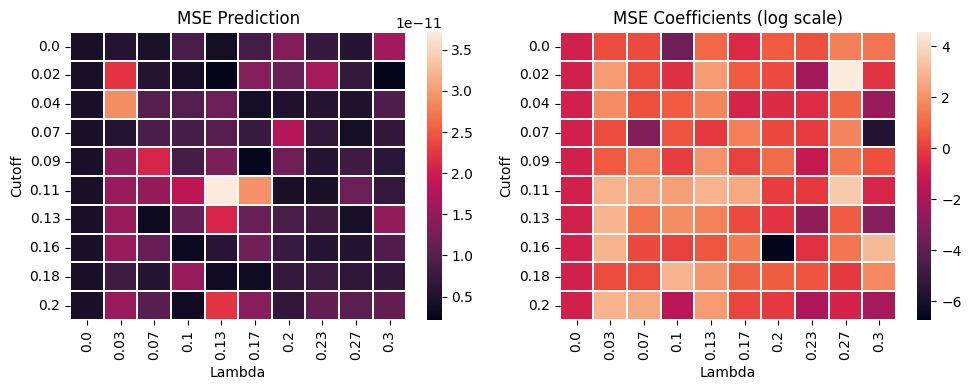

In [8]:
## Heatmap of Errors

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )

fig.tight_layout();

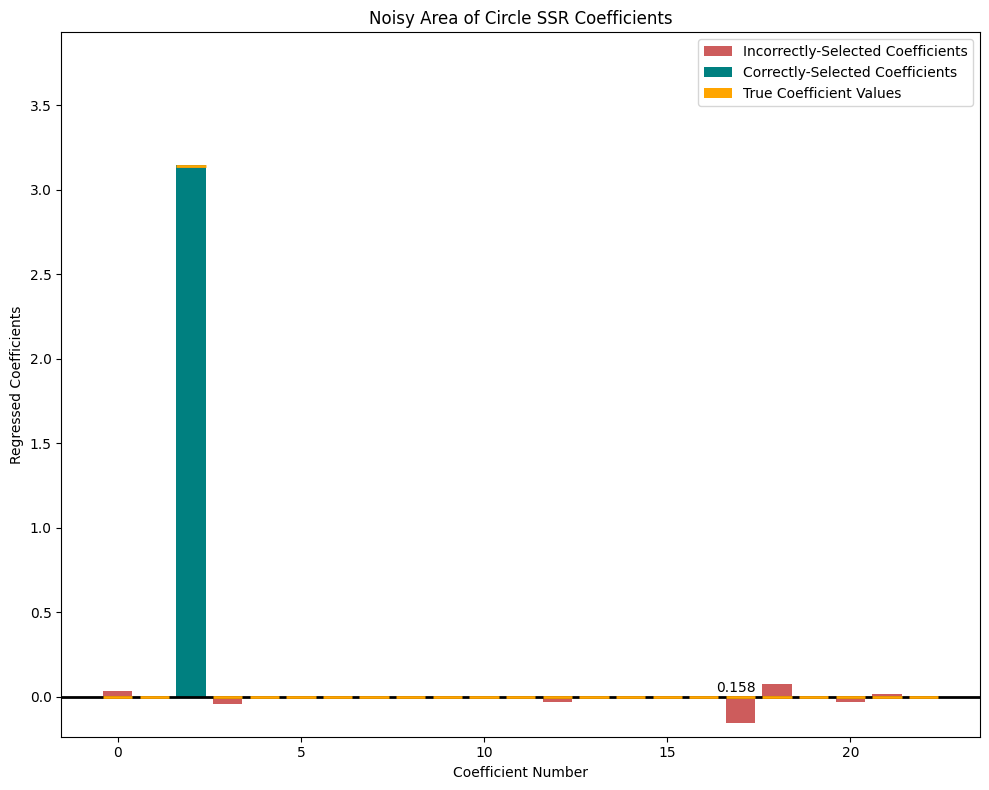

In [9]:
## Barplot of Coefficients

x = xs[MSE_coef.argmin()] ## gets Coefficient with Least Coefficient MSE


expected = np.zeros_like(x)
expected[2] = np.pi

color = np.zeros_like(x, dtype= np.object_)
color[expected > 0] = "teal"
color[expected == 0] = "indianred"

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(x)), height=x.squeeze().tolist(), color = color.ravel().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"Noisy Area of Circle SSR Coefficients")
axes.set_ylim((x.min() + 0.5*x.min(),x.max() + 0.25*x.max()))
axes.tick_params(axis='x', labelsize=10)

for i, exp in enumerate(expected):
    y = 0
    if (exp.item() - x[i] < 0).item():
        y = x[i].item()
    else:
        y = exp.item()

    axes.hlines(y=exp,xmin=i - 0.4,xmax=i + 0.4,color='orange',linewidth=2)
    if np.abs(exp.item() - x[i]) >= 0.1:
        axes.text(i - 0.65,y + 0.03,f"{np.abs(exp.item() - x[i]).item():.3f}")

legend_elements = [
    Patch(facecolor='indianred', label='Category 1'),
    Patch(facecolor='teal', label='Category 2'),
    Patch(facecolor='orange', label='Category 3'),
]
axes.legend(handles=legend_elements, labels=["Incorrectly-Selected Coefficients", "Correctly-Selected Coefficients", "True Coefficient Values"],);

fig.tight_layout();

Noisy Volume of a Cylinder Problem

In [10]:
torch.manual_seed(42)

r = torch.rand(size = (30,1)) * 5 ## setting up r
h = torch.rand(size = (30,1)) * 5 ## setting up h
b = torch.pi * torch.square(r) * h ## setting up volumes

pow = 11 ## for r^0 to r^10
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(r,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(h,torch.meshgrid(powers, powers)[1].reshape(-1,)))


c:\Users\spres\anaconda3\envs\torch_gpu\Lib\site-packages\torch\functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4383.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [11]:
A = torch.concat([B,torch.sin(b), torch.cos(b), torch.tan(b), torch.sqrt(b), torch.log(b), torch.special.erf(b), torch.special.airy_ai(b), torch.special.bessel_j0(b), torch.special.bessel_j1(b), torch.special.ndtr(b), torch.special.legendre_polynomial_p(b,3),  torch.special.legendre_polynomial_p(b,2),torch.sin(h), torch.cos(h), torch.tan(h), torch.sqrt(h), torch.log(h), torch.special.erf(h), torch.special.airy_ai(h), torch.special.bessel_j0(h), torch.special.bessel_j1(h), torch.special.ndtr(h), torch.special.legendre_polynomial_p(h,3),  torch.special.legendre_polynomial_p(h,2)], dim = 1)

In [12]:
torch.linalg.cond(A)

tensor(2.9289e+12)

In [13]:
torch.nonzero(A * torch.pi == b) ## true coefficient is at index 23

tensor([[ 0, 23],
        [ 1, 23],
        [ 3, 23],
        [ 4, 23],
        [ 7, 23],
        [ 8, 23],
        [ 9, 23],
        [10, 23],
        [11, 23],
        [12, 23],
        [14, 23],
        [18, 23],
        [20, 23],
        [21, 23],
        [24, 23],
        [26, 23],
        [28, 23],
        [29, 23]])

In [14]:
lambdas = np.linspace(start = 0, stop = 0.3, num= 10)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 10)

MSE_data = []
MSE_coef = []
xs = []
for ind, i in enumerate(lambdas):
    for j in cutoffs:
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)

        xs.append(x)

        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collecting Prediction MSE

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[23] = torch.pi ## setting true coefficients
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collecting MSE of Coefficients

In [15]:
MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

Avg MSE Prediction: 1400.4676513671875   Max MSE Prediction: 11324.0537109375   Min MSE Prediction: 2.8593103885650635
Avg MSE Coefficients: 0.3280460238456726   Max MSE Coefficients: 0.3314415216445923   Min MSE Coefficients: 0.3252291679382324


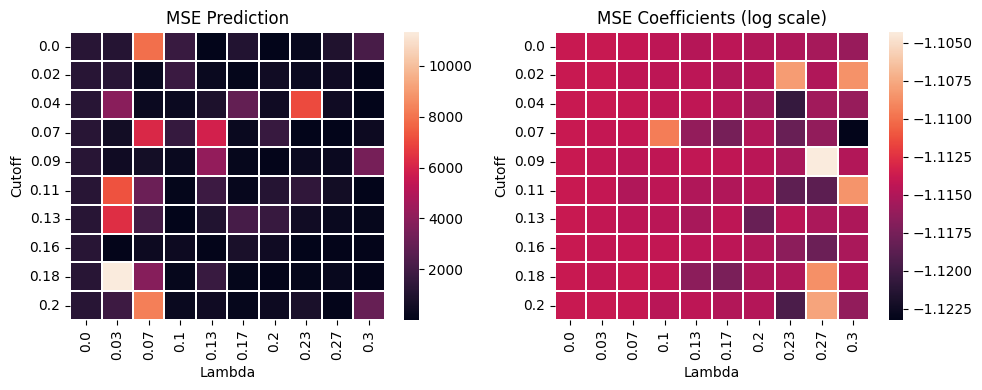

In [16]:
## Heatmap of Errors

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )

fig.tight_layout();

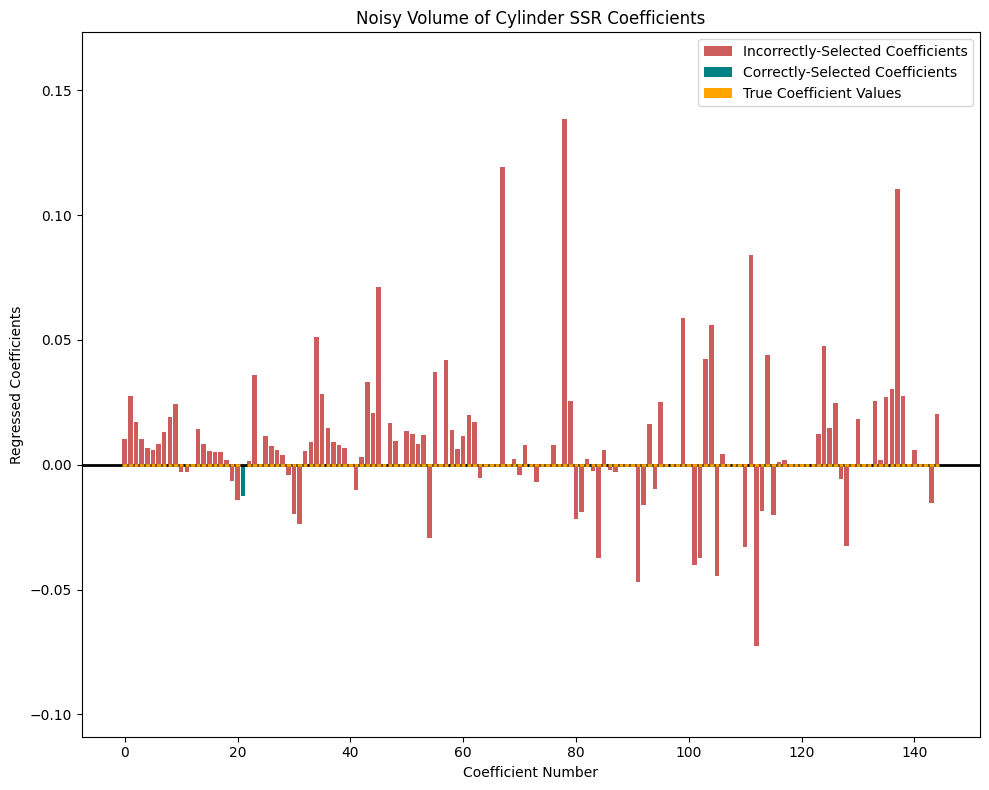

In [17]:
## Bar plot

x = xs[MSE_coef.argmin()] ## gets Coefficient with Least Coefficient MSE



expected = np.zeros_like(x)
expected[21] = np.pi



color = np.zeros_like(x, dtype= np.object_)
color[expected > 0] = "teal"
color[expected == 0] = "indianred"

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(x)), height=x.squeeze().tolist(), color = color.ravel().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"Noisy Volume of Cylinder SSR Coefficients")
axes.set_ylim((x.min() + 0.5*x.min(),x.max() + 0.25*x.max()))
axes.tick_params(axis='x', labelsize=10)

for i, exp in enumerate(expected):
    y = 0
    if (exp.item() - x[i] < 0).item():
        y = x[i].item()
    else:
        y = exp.item()

    axes.hlines(y=exp,xmin=i - 0.4,xmax=i + 0.4,color='orange',linewidth=2)


legend_elements = [
    Patch(facecolor='indianred', label='Category 1'),
    Patch(facecolor='teal', label='Category 2'),
    Patch(facecolor='orange', label='Category 3'),
]
axes.legend(handles=legend_elements, labels=["Incorrectly-Selected Coefficients", "Correctly-Selected Coefficients", "True Coefficient Values"],);

fig.tight_layout();

Rediscovering f(x) = x + x^2

In [18]:
pow = 11
powers = torch.arange(start = 0, end = pow, step = 1) ## getting powers for t^0 to t^10
t = (5) * torch.rand(size = (30,1)) ## initializing t from 0 to 5
B = (torch.pow(t,powers))
b = t + torch.pow(t, 2) ## true values

## Setting up Noisy Library
A = torch.concat([B,torch.sin(t), torch.cos(t), torch.tan(t), torch.sqrt(t), torch.log(t), torch.special.erf(t), torch.special.airy_ai(t), torch.special.bessel_j0(t), torch.special.bessel_j1(t), torch.special.ndtr(t), torch.special.legendre_polynomial_p(t,3),  torch.special.legendre_polynomial_p(t,2)], dim = 1)

lambdas = np.linspace(start = 0, stop = 0.3, num= 10)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 10)

In [19]:
xs = []
MSE_data = []
MSE_coef = []
for ind, i in enumerate(lambdas):
    for j in cutoffs:
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)

        xs.append(x)
        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## Collecting MSE on Predicted Values

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[1] = 1 ## setting true coefficients, since first three columns of A are 0, t, t^2
        exp[2] = 1 ## setting true coefficients
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## Collecting MSE of Coefficients

In [20]:
MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

In [21]:
torch.linalg.cond(A)

tensor(5.5938e+13)

Avg MSE Prediction: 5.364421407083597e-11   Max MSE Prediction: 5.222324350739882e-09   Min MSE Prediction: 1.764490416028986e-14
Avg MSE Coefficients: 0.6002547144889832   Max MSE Coefficients: 13.825703620910645   Min MSE Coefficients: 0.0059731765650212765


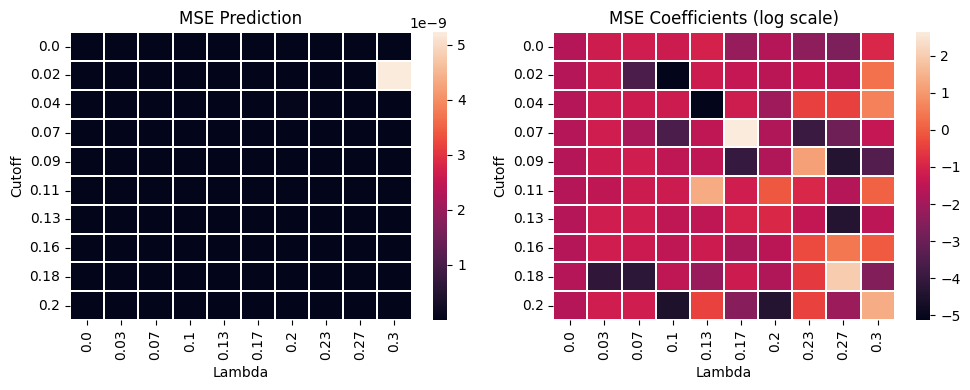

In [22]:
## Heatmaps of MSE

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )
fig.tight_layout();

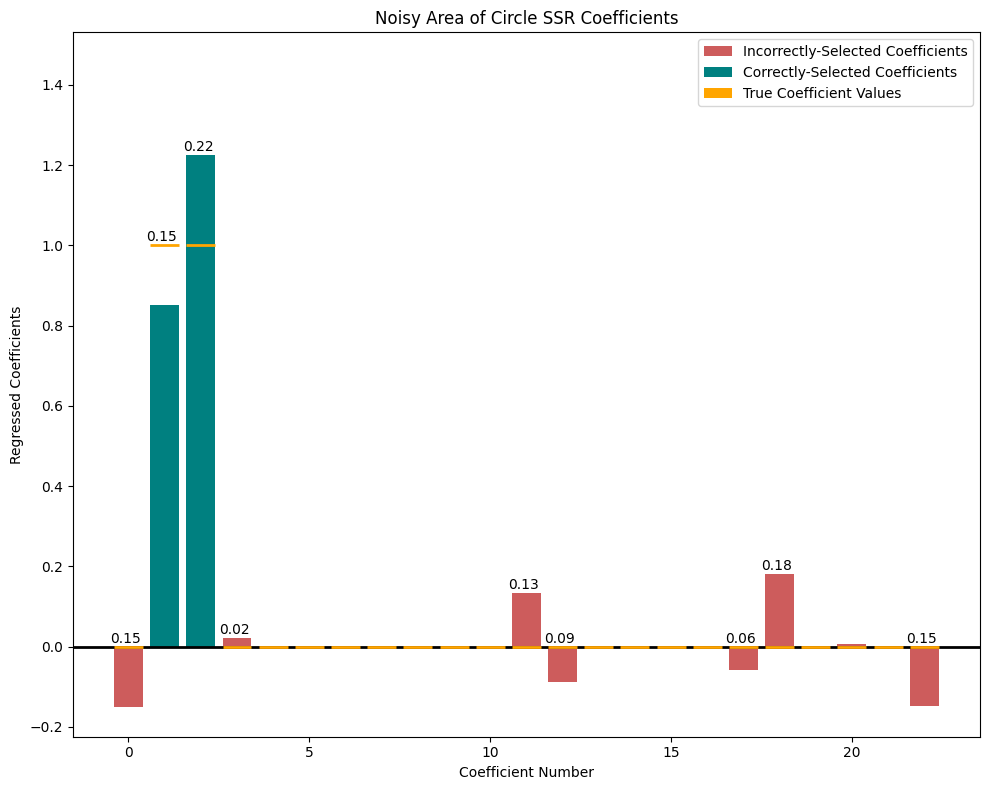

In [23]:
## Barplot of Coefficients

x = xs[MSE_coef.argmin()]


expected = np.zeros_like(x)
expected[1] = 1
expected[2] = 1

color = np.zeros_like(x, dtype= np.object_)
color[expected > 0] = "teal"
color[expected == 0] = "indianred"

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(x)), height=x.squeeze().tolist(), color = color.ravel().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"Noisy Area of Circle SSR Coefficients")
axes.set_ylim((x.min() + 0.5*x.min(),x.max() + 0.25*x.max()))
axes.tick_params(axis='x', labelsize=10)

for i, exp in enumerate(expected):
    y = 0
    if (exp.item() - x[i] < 0).item():
        y = x[i].item()
    else:
        y = exp.item()

    axes.hlines(y=exp,xmin=i - 0.4,xmax=i + 0.4,color='orange',linewidth=2)
    if np.abs(exp.item() - x[i]) >= 0.01:
        axes.text(i - 0.5,y + 0.01,f"{np.abs(exp.item() - x[i]).item():.2f}")

legend_elements = [
    Patch(facecolor='indianred', label='Category 1'),
    Patch(facecolor='teal', label='Category 2'),
    Patch(facecolor='orange', label='Category 3'),
]
axes.legend(handles=legend_elements, labels=["Incorrectly-Selected Coefficients", "Correctly-Selected Coefficients", "True Coefficient Values"],);
fig.tight_layout();

## SIN COMPOSITIONS

Rediscovering $sin(c^2 + d^2)$ 

In [24]:
torch.manual_seed(42)

c = (5) * torch.rand(size = (30,1)) ## Setting up input 1 to be from 0 to 5 for 30 datapoints
d = (5) * torch.rand(size = (30,1)) ## Setting up input 2 to be from 0 to 5 for 30 datapoints

b = torch.sin(c ** 2 + d ** 2) ## true solution

pow = 3
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(c,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(d,torch.meshgrid(powers, powers)[1].reshape(-1,)))

import itertools

## Getting all possible polynomials of Q_3,3

exps = [(i, j) for i in range(3) for j in range(3)]

expressions = []

for i, j in exps:
    m = (c ** i) * (d ** j)

    expressions.append(torch.sin(m))
    
for (i1, j1), (i2, j2) in itertools.combinations(exps, 2):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)
    expressions.append(torch.sin(m1 + m2))

for (i1, j1), (i2, j2), (i3, j3) in itertools.combinations(exps, 3):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)
    expressions.append(torch.sin(m1 + m2 + m3))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4) in itertools.combinations(exps, 4):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5) in itertools.combinations(exps, 5):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6) in itertools.combinations(exps, 6):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7) in itertools.combinations(exps, 7):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6 + m7))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8) in itertools.combinations(exps, 8):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8), (i9, j9) in itertools.combinations(exps, 9):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)

    m9 = (c ** i9) * (d ** j9)
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8 + m9))

A = torch.concat([B,torch.stack(expressions).squeeze()[1:,:].T], dim = 1)

In [25]:
torch.linalg.cond(A)

tensor(88.0305)

In [26]:
torch.nonzero(A == b) ## true coefficient is at 35

tensor([[ 0, 35],
        [ 1, 35],
        [ 2, 35],
        [ 3, 35],
        [ 4, 35],
        [ 5, 35],
        [ 6, 35],
        [ 7, 35],
        [ 8, 35],
        [ 9, 35],
        [10, 35],
        [11, 35],
        [12, 35],
        [13, 35],
        [14, 35],
        [15, 35],
        [16, 35],
        [17, 35],
        [18, 35],
        [19, 35],
        [20, 35],
        [21, 35],
        [22, 35],
        [23, 35],
        [24, 35],
        [25, 35],
        [26, 35],
        [27, 35],
        [28, 35],
        [29, 35]])

Avg MSE Prediction: 1.4482930168189558e-14   Max MSE Prediction: 4.4595796781961294e-14   Min MSE Prediction: 1.9336381522111652e-15
Avg MSE Coefficients: 0.03225424513220787   Max MSE Coefficients: 0.03702757880091667   Min MSE Coefficients: 0.029927145689725876


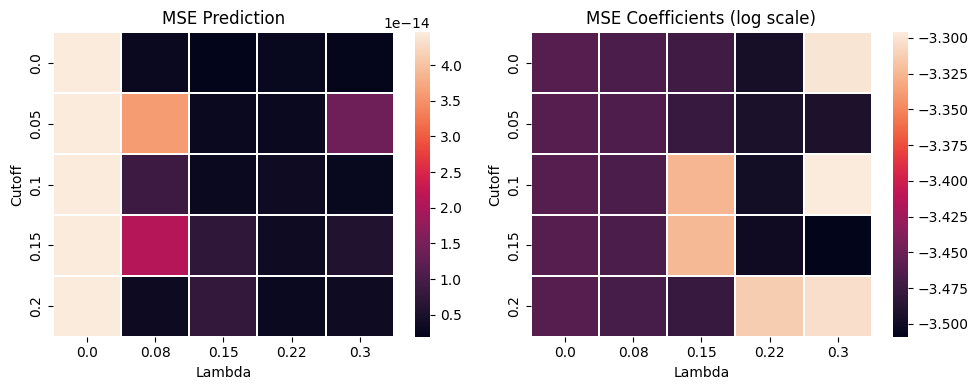

In [27]:
## Heatmaps of MSE
torch.manual_seed(42)

lambdas = np.linspace(start = 0, stop = 0.3, num= 5)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 5)

MSE_data = []
MSE_coef = []
xs = [] 
for ind, i in enumerate(lambdas):
    for j in cutoffs:
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)
        xs.append(x)
        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collecting all Predicted MSE

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[35] = 1 ## setting true coefficient
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collecting all Coefficient MSE

MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )

fig.tight_layout();

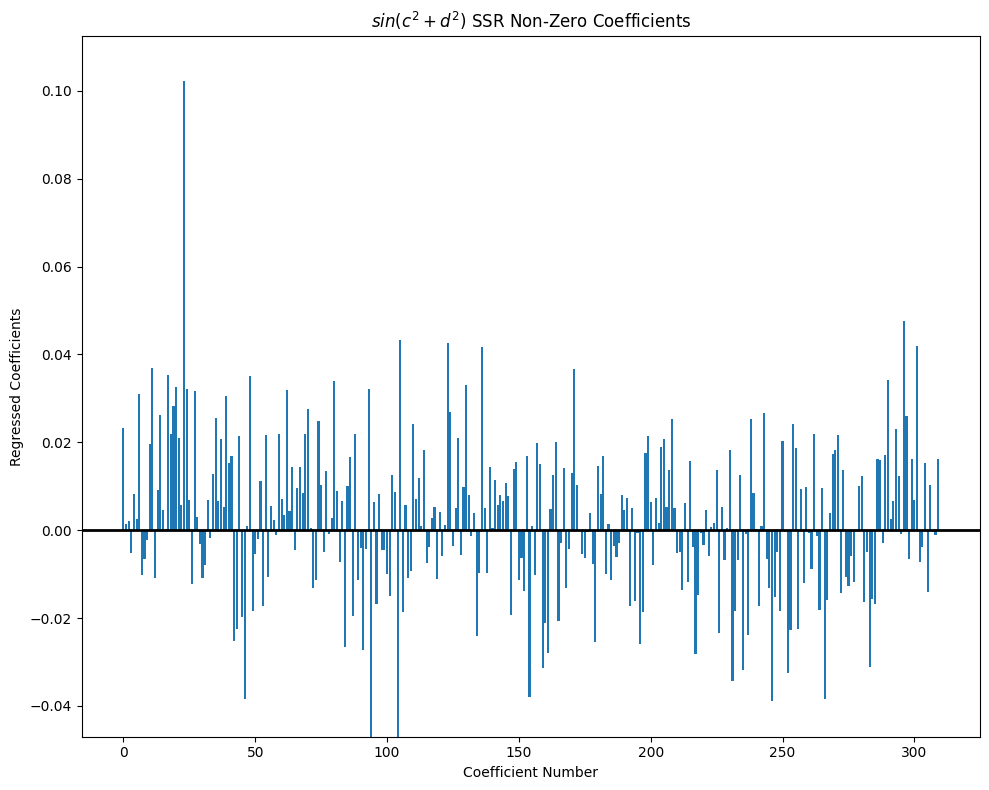

In [28]:
x = xs[MSE_coef.argmin()]

plot_exp = exp[x!=0]
plot_x = x[x!=0]

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(plot_x)), height=plot_x.squeeze().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"$sin(c^2 + d^2)$ SSR Non-Zero Coefficients")
axes.set_ylim((plot_x.min() - 0.1*plot_x.min(),plot_x.max() + 0.1*plot_x.max()))
axes.tick_params(axis='x', labelsize=10)

fig.tight_layout();

Repeating with Expanded Dataset of 1000

In [29]:
torch.manual_seed(42)

c = (5) * torch.rand(size = (1000,1)) ## Expands Dataset to 1000 elements
d = (5) * torch.rand(size = (1000,1)) ## Expands Dataset to 1000 elements

b = torch.sin(c ** 2 + d ** 2) 

pow = 3
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(c,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(d,torch.meshgrid(powers, powers)[1].reshape(-1,)))

import itertools

## Getting all possible polynomials of Q_3,3

exps = [(i, j) for i in range(3) for j in range(3)]

expressions = []

total_idx = 0
for idx, (i, j) in enumerate(exps):
    m = (c ** i) * (d ** j)

    expressions.append(torch.sin(m))

total_idx = idx
for idx, ((i1, j1), (i2, j2)) in enumerate(itertools.combinations(exps, 2)):
    total_idx += 1
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)
    expressions.append(torch.sin(m1 + m2))


for (i1, j1), (i2, j2), (i3, j3) in itertools.combinations(exps, 3):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)
    expressions.append(torch.sin(m1 + m2 + m3))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4) in itertools.combinations(exps, 4):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5) in itertools.combinations(exps, 5):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6) in itertools.combinations(exps, 6):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7) in itertools.combinations(exps, 7):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6 + m7))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8) in itertools.combinations(exps, 8):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8), (i9, j9) in itertools.combinations(exps, 9):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)

    m9 = (c ** i9) * (d ** j9)
    expressions.append(torch.sin(m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8 + m9))

A = torch.concat([B,torch.stack(expressions).squeeze()[1:,:].T], dim = 1)

In [30]:
torch.linalg.cond(A)

tensor(16388.3926)

In [31]:
torch.nonzero(A == b) ## true coefficient is at 35

tensor([[  0,  35],
        [  1,  35],
        [  2,  35],
        ...,
        [997,  35],
        [998,  35],
        [999,  35]])

Avg MSE Prediction: 0.0   Max MSE Prediction: 0.0   Min MSE Prediction: 0.0
Avg MSE Coefficients: 5.3649336476613844e-30   Max MSE Coefficients: 2.681860456824764e-29   Min MSE Coefficients: 0.0


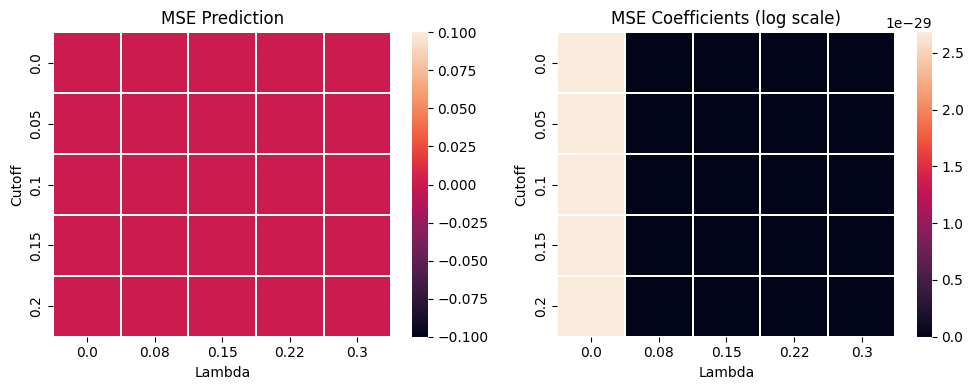

In [32]:
torch.manual_seed(42)

lambdas = np.linspace(start = 0, stop = 0.3, num= 5)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 5)

MSE_data = []
MSE_coef = []
xs = [] 
for ind, i in enumerate(lambdas):
    for j in cutoffs:
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)
        xs.append(x)
        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collecting predicted MSE

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[35] = 1 ## setting up actual coefficients
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collecting MSE of coefficients

MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )

fig.tight_layout();

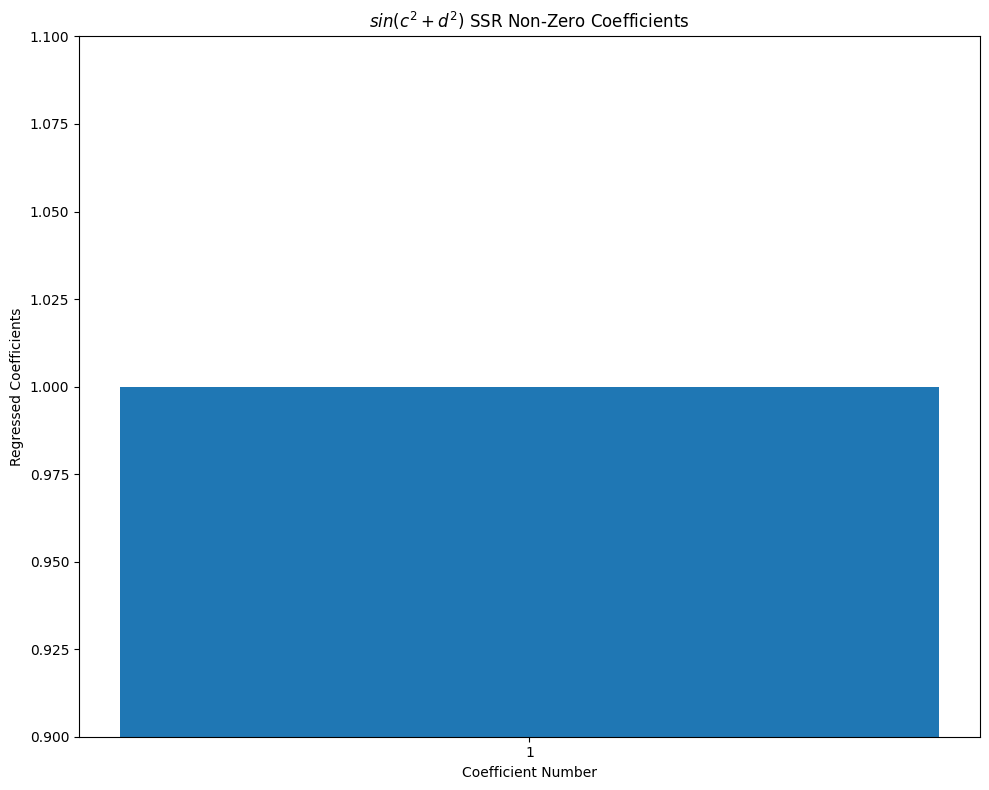

In [33]:
x = xs[MSE_coef.argmin()]

plot_exp = exp[x!=0]
plot_x = x[x!=0]

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(plot_x)), height=plot_x.squeeze().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"$sin(c^2 + d^2)$ SSR Non-Zero Coefficients")
axes.set_ylim((plot_x.min() - 0.1*plot_x.min(),plot_x.max() + 0.1*plot_x.max()))
axes.xaxis.set_ticks([0])
axes.xaxis.set_ticklabels(["1"]);
fig.tight_layout();

Rediscovering $sin(\sqrt{c^2 + d^2})$ 

In [34]:
torch.manual_seed(42)

c = (5) * torch.rand(size = (30,1)) ## initializing inputs
d = (5) * torch.rand(size = (30,1)) ## initializing inputs

b = torch.sin((c ** 2 + d ** 2).sqrt()) ## true value

pow = 3
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(c,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(d,torch.meshgrid(powers, powers)[1].reshape(-1,)))

import itertools

## Getting all possible polynomials of Q_3,3

exps = [(i, j) for i in range(3) for j in range(3)]

expressions = []

for i, j in exps:
    m = (c ** i) * (d ** j)

    expressions.append((m))
    
for (i1, j1), (i2, j2) in itertools.combinations(exps, 2):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)
    expressions.append((m1 + m2))

for (i1, j1), (i2, j2), (i3, j3) in itertools.combinations(exps, 3):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)
    expressions.append((m1 + m2 + m3))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4) in itertools.combinations(exps, 4):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 
    expressions.append((m1 + m2 + m3 + m4))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5) in itertools.combinations(exps, 5):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 
    expressions.append((m1 + m2 + m3 + m4 + m5))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6) in itertools.combinations(exps, 6):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7) in itertools.combinations(exps, 7):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8) in itertools.combinations(exps, 8):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8), (i9, j9) in itertools.combinations(exps, 9):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)

    m9 = (c ** i9) * (d ** j9)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8 + m9))

A = torch.concat([B,torch.sin(torch.stack(expressions)).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).sqrt()).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).square()).squeeze()[1:,:].T], dim = 1)

In [35]:
torch.linalg.cond(A)

tensor(50.5434)

In [36]:
torch.nonzero(torch.all(torch.isclose(A, b), dim=0)) ## true coefficient is at 545

tensor([[545]])

Avg MSE Prediction: 7.516981693133848e-14   Max MSE Prediction: 3.246172319663898e-13   Min MSE Prediction: 4.749094353721523e-15
Avg MSE Coefficients: 0.03315167501568794   Max MSE Coefficients: 0.03401932492852211   Min MSE Coefficients: 0.032645173370838165


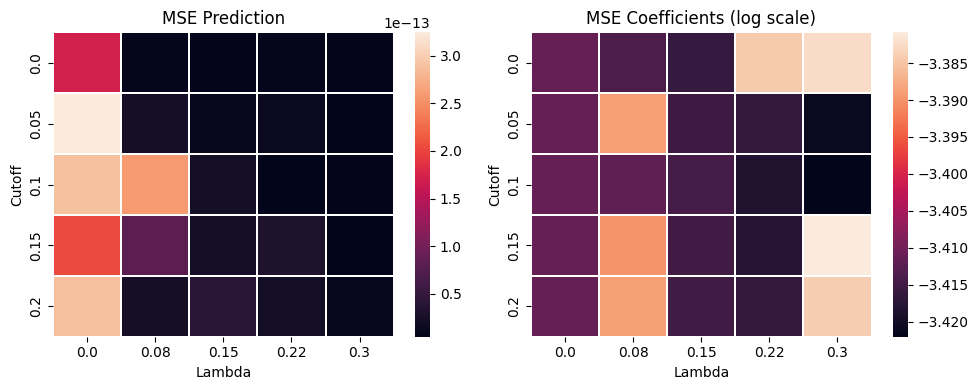

In [37]:
torch.manual_seed(42)

lambdas = np.linspace(start = 0, stop = 0.3, num= 5)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 5)

MSE_data = []
MSE_coef = []
xs = []
for ind, i in enumerate(lambdas):
    for id, j in enumerate(cutoffs):
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)

        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collecting predicted MSE

        xs.append(x)

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[545] = 1 ## setting true coefficients
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collecting Coefficient MSE

MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )

fig.tight_layout();

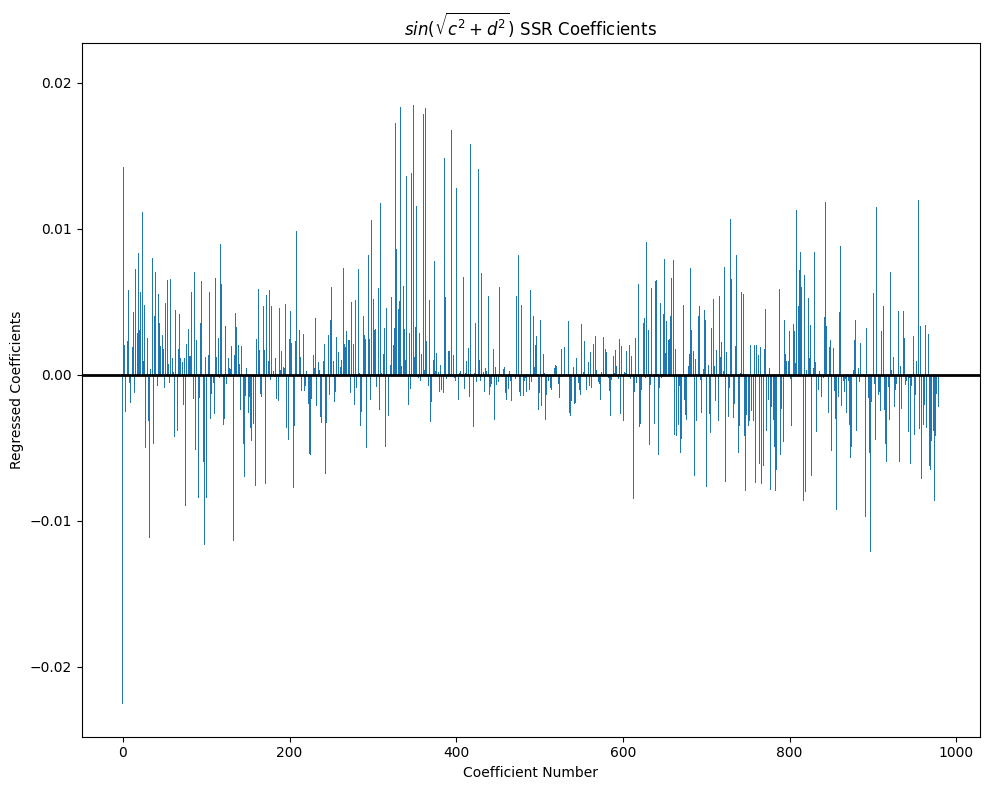

In [38]:
x = xs[(torch.argmin(MSE_coef))]
plot_exp = exp[x!=0]
plot_x = x[x!=0]

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(plot_x)), height=plot_x.squeeze().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"$sin(\sqrt{c^2 + d^2})$ SSR Coefficients")
axes.set_ylim((plot_x.min() + 0.1*plot_x.min(),plot_x.max() + 0.1*plot_x.max()))
axes.tick_params(axis='x', labelsize=10)
fig.tight_layout();

In [39]:
torch.manual_seed(42)

c = (5) * torch.rand(size = (1000,1))
d = (5) * torch.rand(size = (1000,1)) 

b = torch.sin((c ** 2 + d ** 2).sqrt()) 

pow = 3
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(c,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(d,torch.meshgrid(powers, powers)[1].reshape(-1,)))

import itertools

## Getting all possible polynomials of Q_3,3

exps = [(i, j) for i in range(3) for j in range(3)]

expressions = []

for i, j in exps:
    m = (c ** i) * (d ** j)

    expressions.append((m))
    
for (i1, j1), (i2, j2) in itertools.combinations(exps, 2):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)
    expressions.append((m1 + m2))

for (i1, j1), (i2, j2), (i3, j3) in itertools.combinations(exps, 3):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)
    expressions.append((m1 + m2 + m3))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4) in itertools.combinations(exps, 4):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 
    expressions.append((m1 + m2 + m3 + m4))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5) in itertools.combinations(exps, 5):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 
    expressions.append((m1 + m2 + m3 + m4 + m5))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6) in itertools.combinations(exps, 6):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7) in itertools.combinations(exps, 7):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8) in itertools.combinations(exps, 8):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8), (i9, j9) in itertools.combinations(exps, 9):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)

    m9 = (c ** i9) * (d ** j9)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8 + m9))

A = torch.concat([B,torch.sin(torch.stack(expressions)).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).sqrt()).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).square()).squeeze()[1:,:].T], dim = 1)

In [40]:
torch.linalg.cond(A)

tensor(1713989.8750)

In [41]:
print(torch.nonzero(torch.all(A == b, dim=0))) ## true collumn is 545

tensor([[545]])


Avg MSE Prediction: 7.281118524944674e-13   Max MSE Prediction: 6.627336700260056e-12   Min MSE Prediction: 2.1684044479646887e-22
Avg MSE Coefficients: 0.04224560782313347   Max MSE Coefficients: 0.35394740104675293   Min MSE Coefficients: 6.490729857674208e-22


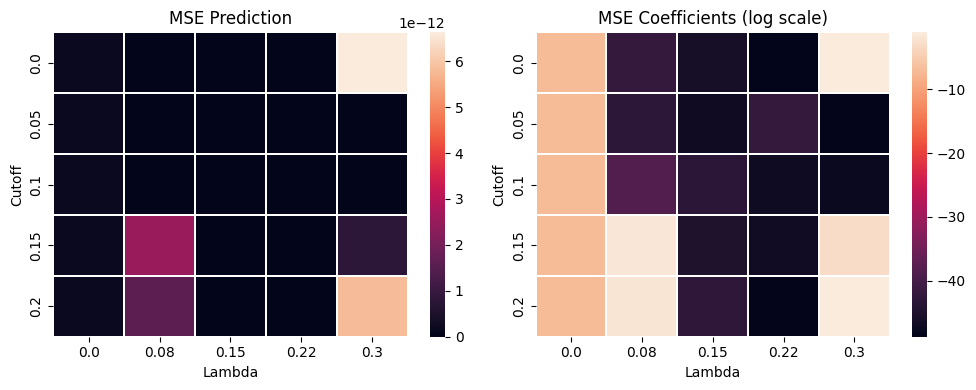

In [42]:
## Heatmap of MSE

torch.manual_seed(42)

lambdas = np.linspace(start = 0, stop = 0.3, num= 5)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 5)

MSE_data = []
MSE_coef = []
xs = []
for ind, i in enumerate(lambdas):
    for id, j in enumerate(cutoffs):
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j)

        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collecting predicted MSE

        xs.append(x)

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[545] = 1 ## true coefficients
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collecting coefficient MSE

MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )
fig.tight_layout();

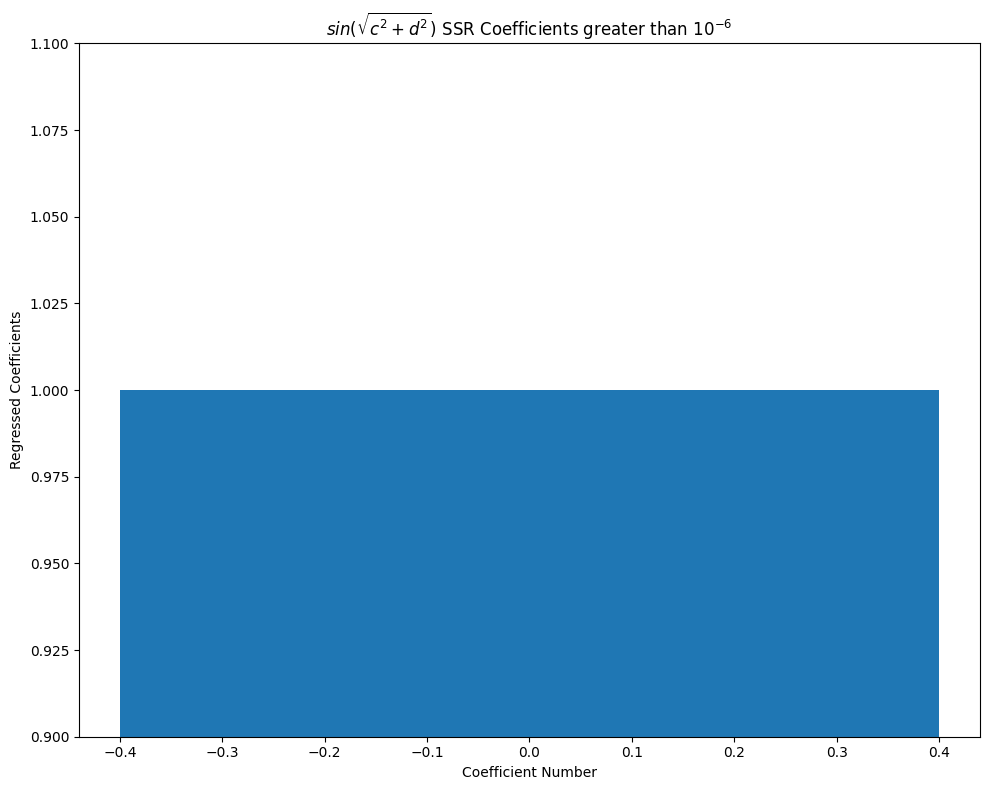

In [43]:
## Barplot of Coefficients

x = xs[(torch.argmin(MSE_coef))]
plot_exp = exp[np.abs(x) >= 1e-6]
plot_x = x[np.abs(x) >= 1e-6]

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(plot_x)), height=plot_x.squeeze().tolist())
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"$sin(\sqrt{c^2 + d^2})$ SSR Coefficients greater than $10^{-6}$")
axes.set_ylim((plot_x.min() - 0.1*plot_x.min(),plot_x.max() + 0.1*plot_x.max()))
axes.tick_params(axis='x', labelsize=10)
fig.tight_layout();

Rediscovering $sin(\sqrt{c^2 + d^2} + cos(c^2+d^2))$ 

In [44]:
torch.manual_seed(42)

c = (5) * torch.rand(size = (2000,1)) ## initializing inputs for 2000 elements
d = (5) * torch.rand(size = (2000,1)) ## initializing inputs for 2000 elements

b = torch.sin((c ** 2 + d ** 2).sqrt() + torch.cos(c ** 2 + d ** 2)) ## true values

pow = 3
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(c,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(d,torch.meshgrid(powers, powers)[1].reshape(-1,)))

In [45]:
import itertools

## Getting all possible polynomials of Q_3,3

exps = [(i, j) for i in range(3) for j in range(3)]

expressions = []

for i, j in exps:
    m = (c ** i) * (d ** j)

    expressions.append((m))
    
for (i1, j1), (i2, j2) in itertools.combinations(exps, 2):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)
    expressions.append((m1 + m2))

for (i1, j1), (i2, j2), (i3, j3) in itertools.combinations(exps, 3):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)
    expressions.append((m1 + m2 + m3))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4) in itertools.combinations(exps, 4):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 
    expressions.append((m1 + m2 + m3 + m4))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5) in itertools.combinations(exps, 5):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 
    expressions.append((m1 + m2 + m3 + m4 + m5))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6) in itertools.combinations(exps, 6):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7) in itertools.combinations(exps, 7):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8) in itertools.combinations(exps, 8):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8), (i9, j9) in itertools.combinations(exps, 9):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)

    m9 = (c ** i9) * (d ** j9)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8 + m9))

A = torch.concat([B,torch.sin(torch.stack(expressions) + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions) - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions) + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions) - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).square() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).square() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions).square() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions).square() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions).sqrt() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,-torch.sin(torch.stack(expressions).sqrt() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).sqrt() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).sqrt() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T, torch.sin(torch.cos(torch.stack(expressions))).squeeze()[1:,:].T, torch.sin(torch.cos(torch.stack(expressions).square())).squeeze()[1:,:].T, torch.sin(torch.cos(torch.stack(expressions))).squeeze()[1:,:].T, torch.sin(torch.stack(expressions)).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).sqrt()).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).square()).squeeze()[1:,:].T], dim = 1)
A = torch.unique(A, dim = 1)

torch.linalg.cond(A)

tensor(964887.1875)

In [46]:
print(torch.nonzero(torch.all(A == b, dim=0))) ## true collumn is 463

tensor([[463]])


Avg MSE Prediction: 1.2937074710659725e-14   Max MSE Prediction: 1.7287195370400792e-14   Min MSE Prediction: 1.056387219860273e-14
Avg MSE Coefficients: 0.00041111980681307614   Max MSE Coefficients: 0.0004323609173297882   Min MSE Coefficients: 0.00037898868322372437


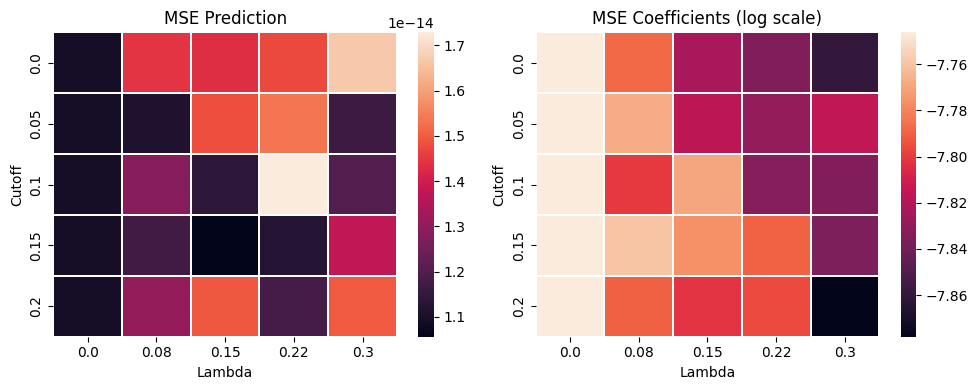

In [47]:
## Heatmap of MSE

torch.manual_seed(42)

lambdas = np.linspace(start = 0, stop = 0.3, num= 5)
cutoffs = np.linspace(start = 0, stop = 0.2, num= 5)

MSE_data = []
MSE_coef = []
xs = []
for ind, i in enumerate(lambdas):
    for id, j in enumerate(cutoffs):
        x = FISTA(A, b, epochs= 10000, lamb = i, cutoff = j) ## FISTA optimization

        MSE_data.append(torch.linalg.norm(A @ torch.from_numpy(x) - b, ord = 2).square() / A.shape[0]) ## collecting predicted MSE

        xs.append(x)

        exp = torch.zeros_like(torch.from_numpy(x))
        exp[463] = 1
        MSE_coef.append(torch.linalg.norm(torch.from_numpy(x) - exp, ord = 2).square() / A.shape[0]) ## collecting coefficient MSE

MSE_data = torch.stack(MSE_data)
MSE_coef = torch.stack(MSE_coef)

fig, axes = plt.subplots(1,2, figsize = (10,4))
sns.heatmap((MSE_data).numpy().reshape(len(cutoffs), len(lambdas)), ax = axes[0], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1)

sns.heatmap(np.log((MSE_coef).numpy()).reshape(len(cutoffs), len(lambdas)), ax = axes[1], xticklabels=np.round(lambdas,2),
    yticklabels=np.round(cutoffs,2),linewidths=0.1);

axes[0].set_title("MSE Prediction")
axes[1].set_title("MSE Coefficients (log scale)")

axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("Cutoff")

axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("Cutoff");

print(f"Avg MSE Prediction: {sum(MSE_data) / len(MSE_data)}   Max MSE Prediction: {max(MSE_data)}   Min MSE Prediction: {min(MSE_data)}" )
print(f"Avg MSE Coefficients: {sum(MSE_coef) / len(MSE_coef)}   Max MSE Coefficients: {max(MSE_coef)}   Min MSE Coefficients: {min(MSE_coef)}" )
fig.tight_layout();

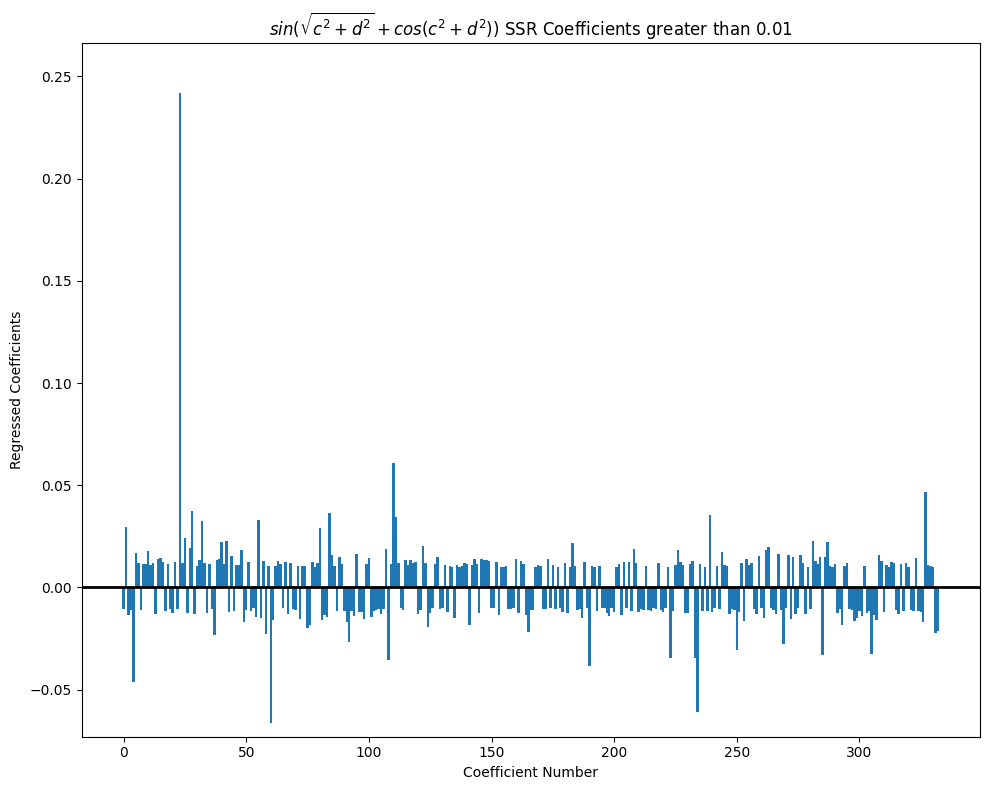

In [48]:
## Barplot of Coefficients

x = xs[torch.argmin(MSE_coef)]
plot_exp = exp[np.abs(x) > 0.01]
plot_x = x[np.abs(x) > 0.01]

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(plot_x)), height=plot_x.squeeze().tolist(), width=1)
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"$sin(\sqrt{c^2 + d^2} + cos(c^2 + d^2))$ SSR Coefficients greater than 0.01")
axes.set_ylim((plot_x.min() + 0.1*plot_x.min(),plot_x.max() + 0.1*plot_x.max()));
fig.tight_layout();

Expanding the Dataset

In [49]:
torch.manual_seed(42)

c = (5) * torch.rand(size = (10000,1)) ## initializing inputs for 10,000 elements
d = (5) * torch.rand(size = (10000,1)) ## initializing inputs for 10,000 elements

b = torch.sin((c ** 2 + d ** 2).sqrt() + torch.cos(c ** 2 + d ** 2)) ## true values for inputs

pow = 3
powers = torch.arange(start = 0, end = pow, step = 1)

B = (torch.pow(c,torch.meshgrid(powers, powers)[0].reshape(-1,)) * torch.pow(d,torch.meshgrid(powers, powers)[1].reshape(-1,)))

import itertools

## Getting all possible polynomials of Q_3,3

exps = [(i, j) for i in range(3) for j in range(3)]

expressions = []

for i, j in exps:
    m = (c ** i) * (d ** j)

    expressions.append((m))
    
for (i1, j1), (i2, j2) in itertools.combinations(exps, 2):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)
    expressions.append((m1 + m2))

for (i1, j1), (i2, j2), (i3, j3) in itertools.combinations(exps, 3):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)
    expressions.append((m1 + m2 + m3))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4) in itertools.combinations(exps, 4):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 
    expressions.append((m1 + m2 + m3 + m4))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5) in itertools.combinations(exps, 5):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 
    expressions.append((m1 + m2 + m3 + m4 + m5))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6) in itertools.combinations(exps, 6):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7) in itertools.combinations(exps, 7):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8) in itertools.combinations(exps, 8):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8))

for (i1, j1), (i2, j2), (i3, j3), (i4, j4), (i5, j5), (i6, j6), (i7, j7), (i8, j8), (i9, j9) in itertools.combinations(exps, 9):
    m1 = (c ** i1) * (d ** j1)

    m2 = (c ** i2) * (d ** j2)

    m3 = (c ** i3) * (d ** j3)

    m4 = (c ** i4) * (d ** j4) 

    m5 = (c ** i5) * (d ** j5) 

    m6 = (c ** i6) * (d ** j6) 

    m7 = (c ** i7) * (d ** j7) 

    m8 = (c ** i8) * (d ** j8)

    m9 = (c ** i9) * (d ** j9)
    expressions.append((m1 + m2 + m3 + m4 + m5 + m6 + m7 + m8 + m9))

A = torch.concat([B,torch.sin(torch.stack(expressions) + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions) - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions) + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions) - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).square() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).square() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions).square() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions).square() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(-torch.stack(expressions).sqrt() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,-torch.sin(torch.stack(expressions).sqrt() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).sqrt() - torch.cos(torch.stack(expressions))).squeeze()[1:,:].T,torch.sin(torch.stack(expressions).sqrt() + torch.cos(torch.stack(expressions))).squeeze()[1:,:].T, torch.sin(torch.cos(torch.stack(expressions))).squeeze()[1:,:].T, torch.sin(torch.cos(torch.stack(expressions).square())).squeeze()[1:,:].T, torch.sin(torch.cos(torch.stack(expressions))).squeeze()[1:,:].T, torch.sin(torch.stack(expressions)).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).sqrt()).squeeze()[1:,:].T, torch.sin(torch.stack(expressions).square()).squeeze()[1:,:].T], dim = 1)
A = torch.unique(A, dim = 1)

torch.linalg.cond(A)

tensor(2.7079e+10)

In [ ]:
torch.manual_seed(42)

x = FISTA(A, b, epochs= 10000, lamb = 3e-1, cutoff = 3e-1)

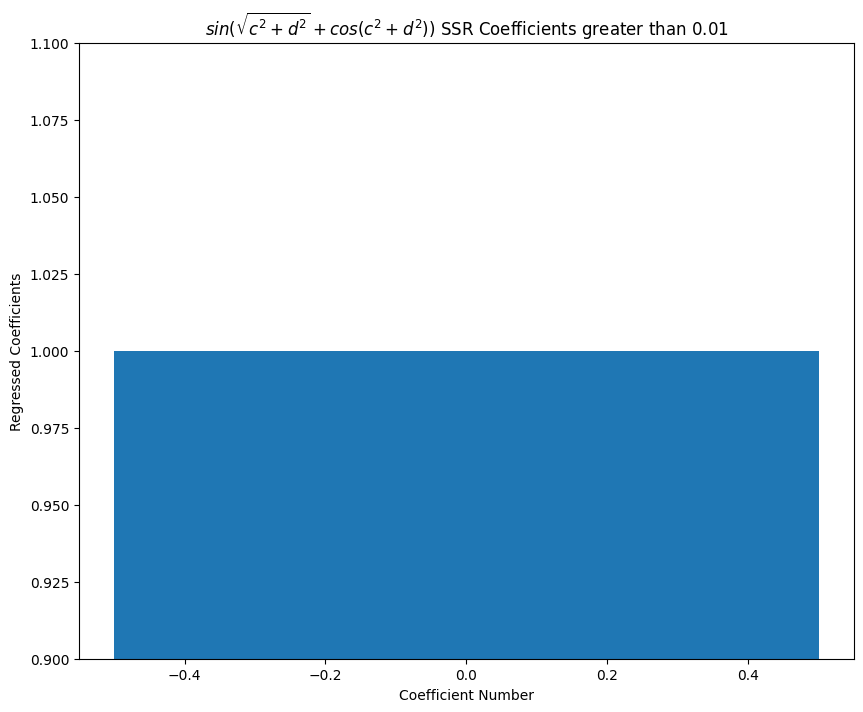

In [ ]:
## Coefficient Barplot

exp = torch.zeros_like(torch.from_numpy(x))
exp[657] = 1 ## setting true coefficients, found earlier

plot_exp = exp[np.abs(x) > 0.01]
plot_x = x[np.abs(x) > 0.01]

fig, axes = plt.subplots(1,1, figsize = (10,8))

axes.bar(x=np.arange(len(plot_x)), height=plot_x.squeeze().tolist(), width=1)
axes.axhline(y = 0, color = "black", linewidth = 2)
    
axes.set_xlabel("Coefficient Number")
axes.set_ylabel("Regressed Coefficients")
axes.set_title(r"$sin(\sqrt{c^2 + d^2} + cos(c^2 + d^2))$ SSR Coefficients greater than 0.01")
axes.set_ylim((plot_x.max() - 0.1,plot_x.max() + 0.1*plot_x.max()));
fig.tight_layout();